# PDB / RRI / Packet Size Sweep Evaluation

This notebook evaluates the new `run_pdb_sweep.sh` output from `results_pdb/all_runs.csv`.
It focuses on the key metrics added for the sweep: BLER, PRR, PIR, and used subchannels × slots.

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'figure.figsize': (8, 5),
})
sns.set(style='whitegrid')

In [8]:
DATA_ROOT = Path('results_pdb')
ALL_RUNS = DATA_ROOT / 'all_runs.csv'
assert ALL_RUNS.exists(), f'Cannot find {ALL_RUNS}'

df = pd.read_csv(ALL_RUNS)
df.columns = [c.strip() for c in df.columns]
for c in ['mcs', 'harq', 'packet_size_bytes', 'pdb_ms', 'rri_ms', 'psfch_period', 'seed']:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

df['prr'] = pd.to_numeric(df['prr'], errors='coerce')
df['pir_sec'] = pd.to_numeric(df['pir_sec'], errors='coerce')
df['pir_ms'] = df['pir_sec'] * 1000.0
df['prr_pct'] = df['prr'] * 100.0
df['used_subch_per_tb'] = np.where(df['total_tbs'] > 0, df['used_subch_slots'] / df['total_tbs'], np.nan)

display(df.head())

,mcs,distance_m,channel_condition,speed_kmh,harq,packet_size_bytes,pdb_ms,rri_ms,psfch_period,total_tbs,...,bler,prr,mean_sinr_db,pir_sec,used_subch_slots,seed,run_id,pir_ms,prr_pct,used_subch_per_tb
0,11,100,nlosv,0,0,1000,100,100,0,0,...,-1,-1,-999,-1,0,1,mcs11_pktSize1000B_pdb100ms_harq0_d100_nlosv_v...,-1000.0,-100.0,NaN
1,11,100,nlosv,0,0,1000,100,100,0,0,...,-1,-1,-999,-1,0,2,mcs11_pktSize1000B_pdb100ms_harq0_d100_nlosv_v...,-1000.0,-100.0,NaN
2,11,100,nlosv,0,0,1000,100,100,0,0,...,-1,-1,-999,-1,0,3,mcs11_pktSize1000B_pdb100ms_harq0_d100_nlosv_v...,-1000.0,-100.0,NaN
3,11,100,nlosv,0,1,1000,100,100,1,0,...,-1,-1,-999,-1,0,1,mcs11_pktSize1000B_pdb100ms_harq1_psfch1_d100_...,-1000.0,-100.0,NaN
4,11,100,nlosv,0,1,1000,100,100,1,0,...,-1,-1,-999,-1,0,2,mcs11_pktSize1000B_pdb100ms_harq1_psfch1_d100_...,-1000.0,-100.0,NaN


In [9]:
print('Rows:', len(df))
print('Unique MCS:', sorted(df['mcs'].dropna().unique()))
print('HARQ values:', sorted(df['harq'].dropna().unique()))
print('PSFCH values:', sorted(df['psfch_period'].dropna().unique()))
print('Packet sizes:', sorted(df['packet_size_bytes'].dropna().unique()))
print('PDB values:', sorted(df['pdb_ms'].dropna().unique()))
print('RRI values:', sorted(df['rri_ms'].dropna().unique()))

Rows: 1728
Unique MCS: [np.int64(5), np.int64(9), np.int64(11), np.int64(15), np.int64(19), np.int64(23)]
HARQ values: [np.int64(0), np.int64(1)]
PSFCH values: [np.int64(0), np.int64(1), np.int64(2), np.int64(4)]
Packet sizes: [np.int64(100), np.int64(500), np.int64(1000), np.int64(2000), np.int64(4000), np.int64(6000)]
PDB values: [np.int64(10), np.int64(20), np.int64(40), np.int64(100)]
RRI values: [np.int64(10), np.int64(20), np.int64(40), np.int64(100)]


## PRR and BLER vs MCS by HARQ and PSFCH Period

/var/folders/th/7_zzpgm11k39lm9k65k2296w0000gn/T/ipykernel_6267/2092419142.py:17: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axes[1].set_yscale('log')


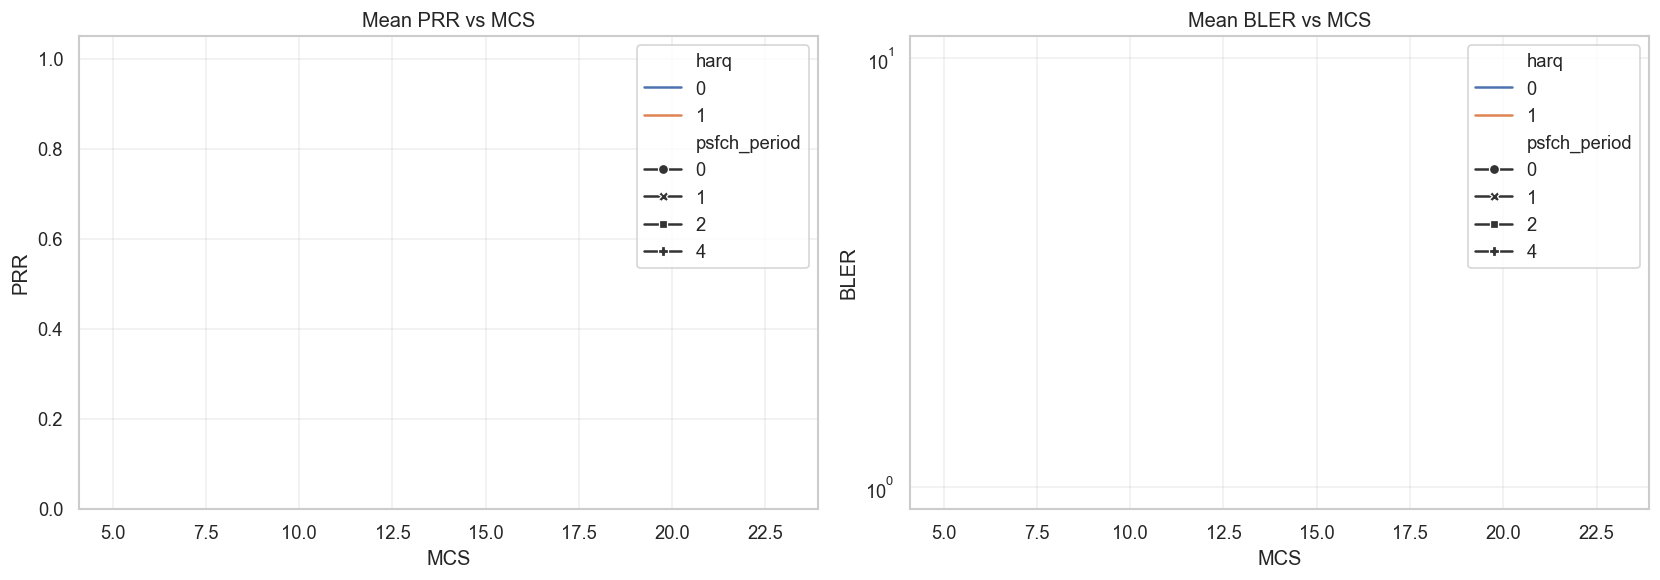

In [10]:
agg = df.groupby(['mcs', 'harq', 'psfch_period']).agg(
    bler_mean=('bler', 'mean'),
    prr_mean=('prr', 'mean'),
    count=('run_id', 'count')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
sns.lineplot(data=agg, x='mcs', y='prr_mean', hue='harq', style='psfch_period', markers=True, dashes=False, ax=axes[0])
axes[0].set_title('Mean PRR vs MCS')
axes[0].set_ylabel('PRR')
axes[0].set_ylim(0, 1.05)
axes[0].grid(True, alpha=0.3)

sns.lineplot(data=agg, x='mcs', y='bler_mean', hue='harq', style='psfch_period', markers=True, dashes=False, ax=axes[1])
axes[1].set_title('Mean BLER vs MCS')
axes[1].set_ylabel('BLER')
axes[1].set_yscale('log')
axes[1].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xlabel('MCS')
plt.tight_layout()

## PIR and Resource Usage vs Packet Size

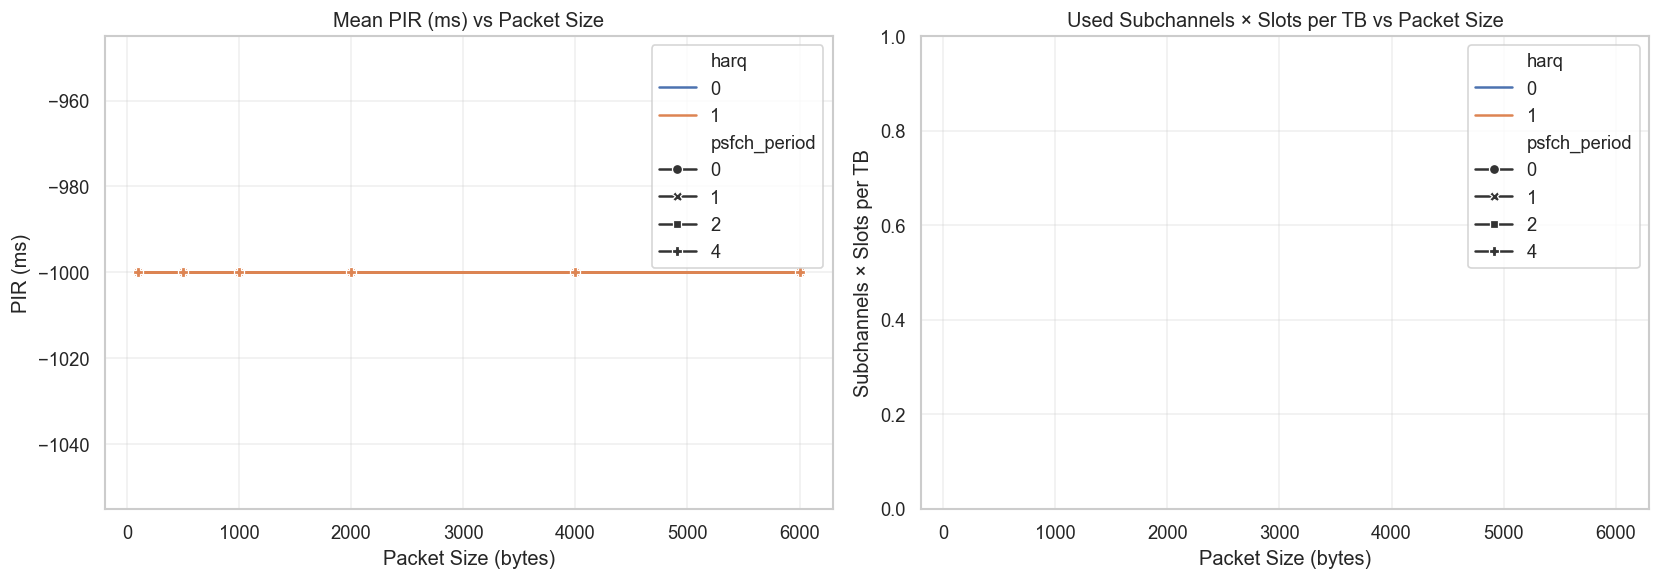

In [11]:
agg2 = df.groupby(['packet_size_bytes', 'harq', 'psfch_period']).agg(
    pir_ms_mean=('pir_ms', 'mean'),
    used_subch_per_tb_mean=('used_subch_per_tb', 'mean'),
    count=('run_id', 'count')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
sns.lineplot(data=agg2, x='packet_size_bytes', y='pir_ms_mean', hue='harq', style='psfch_period', markers=True, dashes=False, ax=axes[0])
axes[0].set_title('Mean PIR (ms) vs Packet Size')
axes[0].set_ylabel('PIR (ms)')
axes[0].grid(True, alpha=0.3)

sns.lineplot(data=agg2, x='packet_size_bytes', y='used_subch_per_tb_mean', hue='harq', style='psfch_period', markers=True, dashes=False, ax=axes[1])
axes[1].set_title('Used Subchannels × Slots per TB vs Packet Size')
axes[1].set_ylabel('Subchannels × Slots per TB')
axes[1].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xlabel('Packet Size (bytes)')
plt.tight_layout()

## Summary Table for Key Dimensions

In [12]:
summary = df.groupby(['mcs', 'packet_size_bytes', 'pdb_ms', 'rri_ms', 'harq', 'psfch_period']).agg(
    bler_mean=('bler', 'mean'),
    prr_mean=('prr', 'mean'),
    pir_ms_mean=('pir_ms', 'mean'),
    used_subch_per_tb_mean=('used_subch_per_tb', 'mean'),
    runs=('run_id', 'count')
).reset_index()
summary.sort_values(['mcs', 'packet_size_bytes', 'harq', 'psfch_period'], inplace=True)
summary.head(20)

,mcs,packet_size_bytes,pdb_ms,rri_ms,harq,psfch_period,bler_mean,prr_mean,pir_ms_mean,used_subch_per_tb_mean,runs
0,5,100,10,10,0,0,-1.0,-1.0,-1000.0,NaN,3
4,5,100,20,20,0,0,-1.0,-1.0,-1000.0,NaN,3
8,5,100,40,40,0,0,-1.0,-1.0,-1000.0,NaN,3
12,5,100,100,100,0,0,-1.0,-1.0,-1000.0,NaN,3
1,5,100,10,10,1,1,-1.0,-1.0,-1000.0,NaN,3
5,5,100,20,20,1,1,-1.0,-1.0,-1000.0,NaN,3
9,5,100,40,40,1,1,-1.0,-1.0,-1000.0,NaN,3
13,5,100,100,100,1,1,-1.0,-1.0,-1000.0,NaN,3
2,5,100,10,10,1,2,-1.0,-1.0,-1000.0,NaN,3
6,5,100,20,20,1,2,-1.0,-1.0,-1000.0,NaN,3
